In [2]:
import pandas as pd
import numpy as np
from datasets import load_dataset

dataset = load_dataset('stanfordnlp/imdb')
df_train = pd.DataFrame(dataset['train'])
df_test = pd.DataFrame(dataset['test'])

print ("Train shape: ", df_train.shape)
print ("Test shape: ", df_test.shape)
print (df_train.head())

C:\Users\Shria\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train shape:  (25000, 2)
Test shape:  (25000, 2)
                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0


## About the IMDB Movie Reviews Dataset

The IMDB Movie Reviews dataset is a text dataset used for sentiment analysis. It contains 50,000 movie reviews from the Internet Movie Database (IMDB).

The dataset is divided into:
- 25,000 training reviews
- 25,000 testing reviews

Each review has two columns:
- **text**: The actual movie review.
- **label**: The sentiment of the review.

The labels are:
- **0 = Negative**
- **1 = Positive**

The training data can be used to develop a sentiment analysis model, while the test data can be used to evaluate the model on unseen reviews.

In [3]:
print("Label distribution:")
print(df_train["label"].value_counts())

print("\nLabel distribution with names:")
print(
    df_train["label"]
    .value_counts()
    .rename(index={
        0: "Negative",
        1: "Positive"
    })
)

Label distribution:
label
0    12500
1    12500
Name: count, dtype: int64

Label distribution with names:
label
Negative    12500
Positive    12500
Name: count, dtype: int64


================================================================== SECTION 2 - TEXT CLEANING ==================================================================

In [4]:
print('label_counts: ')
print(df_train['label'].value_counts())
print('0 = Negative, 1 = positive')

label_counts: 
label
0    12500
1    12500
Name: count, dtype: int64
0 = Negative, 1 = positive


In [5]:
df_train['word_count'] = df_train['text'].apply(
    lambda x: len(x.split())
)

print('Average word count:', df_train['word_count'].mean().round(1))
print('Max word count:    ', df_train['word_count'].max())
print('Min word count:    ', df_train['word_count'].min())

Average word count: 233.8
Max word count:     2470
Min word count:     10


In [6]:
import re

def clean_text(text):
    text = re.sub(r'<.*?>', '', text)       
    text = text.lower()                     
    text = re.sub(r'[^a-z\s]', '', text)    
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_train['clean_text'] = df_train['text'].apply(clean_text)
df_test['clean_text'] = df_test['text'].apply(clean_text)

print('Before:', df_train['text'].iloc[0][:200])
print('After: ', df_train['clean_text'].iloc[0][:200])

Before: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ev
After:  i rented i am curiousyellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it was seized by us customs if it ever tried 


## Raw Text vs. Cleaned Text

The raw IMDB reviews may contain HTML tags, inconsistent capitalization, punctuation, digits, and unnecessary whitespace.

The cleaning process improves consistency:

1. **HTML removal:** Removes formatting tags such as `<br />` that are not part of the actual review.
2. **Lowercasing:** Treats words such as `GOOD` and `good` consistently.
3. **Special-character removal:** Removes punctuation and digits that are not required by this basic preprocessing approach.
4. **Whitespace normalization:** Removes extra spaces and makes the text easier to process.

Cleaning reduces irrelevant variation in the text. However, preprocessing must be chosen carefully because punctuation and other text features can sometimes carry sentiment information.

 ============================================================== SECTION 3 - TEXT VECTORIZATION ===================================================================

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(df_train['clean_text'])
X_test_tfidf = tfidf.transform(df_test['clean_text'])

print('Train matrix shape:', X_train_tfidf.shape)
print('Test matrix shape: ', X_test_tfidf.shape)

Train matrix shape: (25000, 5000)
Test matrix shape:  (25000, 5000)


In [8]:
feature_names = tfidf.get_feature_names_out()
print('Sample features:', feature_names[:20])

Sample features: ['abandoned' 'abc' 'abilities' 'ability' 'able' 'abraham' 'abrupt'
 'absence' 'absent' 'absolute' 'absolutely' 'absurd' 'absurdity' 'abuse'
 'abused' 'abusive' 'abysmal' 'academy' 'accent' 'accents']


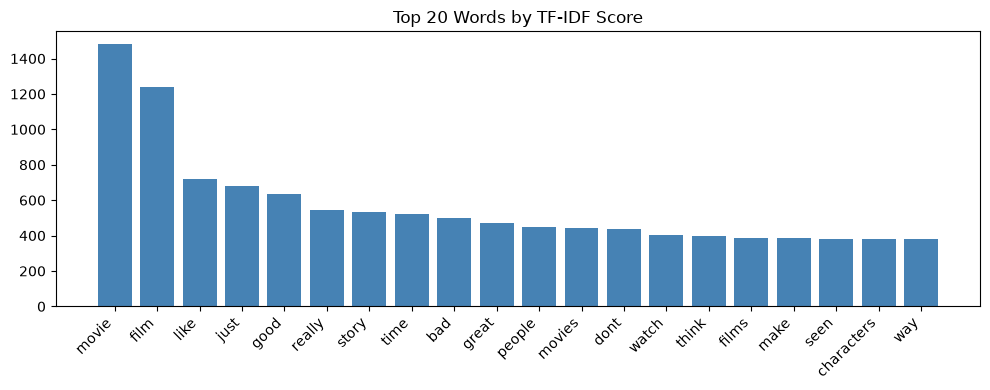

In [9]:
import matplotlib.pyplot as plt

word_freq = np.asarray(X_train_tfidf.sum(axis=0)).flatten()

top_idx = word_freq.argsort()[-20:][::-1]
top_words = [feature_names[i] for i in top_idx]
top_freq = [word_freq[i] for i in top_idx]

plt.figure(figsize=(10, 4))
plt.bar(top_words, top_freq, color='steelblue')
plt.title('Top 20 Words by TF-IDF Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('top_words.png')
plt.show()

## Interpretation of Top 20 TF-IDF Words

The chart shows the 20 words with the highest total TF-IDF scores across the training dataset.

Words such as `movie`, `film`, `story`, and `characters` are mainly related to movie content and are generally neutral. Words such as `good` and `great` are usually associated with positive sentiment, while `bad` may indicate negative sentiment. Words such as `like`, `really`, and `dont` can express different sentiments depending on their context.

The words `movie` and `film` have the highest total scores because they are widely used across movie reviews. However, a high TF-IDF total does not automatically mean that a word is a strong sentiment predictor.

This visualization helps us understand the vocabulary of the dataset and shows how TF-IDF converts text into numerical features that can be used by machine learning models.

 ================================================================== SECTION 4 - EXPLORATORY DATA ANALYSIS ===========================================================

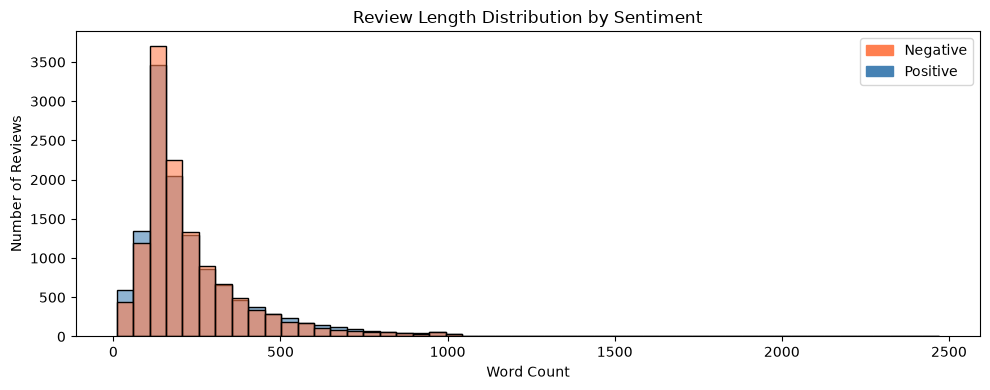

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))

sns.histplot(
    data=df_train,
    x='word_count',
    hue='label',
    bins=50,
    palette={0: 'coral', 1: 'steelblue'},
    alpha=0.6
)

plt.title('Review Length Distribution by Sentiment')
plt.xlabel('Word Count')
plt.ylabel('Number of Reviews')
plt.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color='coral'),
        plt.Rectangle((0, 0), 1, 1, color='steelblue')
    ],
    labels=['Negative', 'Positive']
)

plt.tight_layout()
plt.savefig('length_distribution.png')
plt.show()


**Interpretation : Review Length Distribution**

The histogram shows that both positive and negative reviews have similar length distributions, with most reviews containing approximately 100–250 words. The distributions are right-skewed, meaning that while most reviews are relatively short, a small number of reviews are much longer. The substantial overlap between the two distributions suggests that review length alone may not be sufficient to distinguish positive reviews from negative ones.

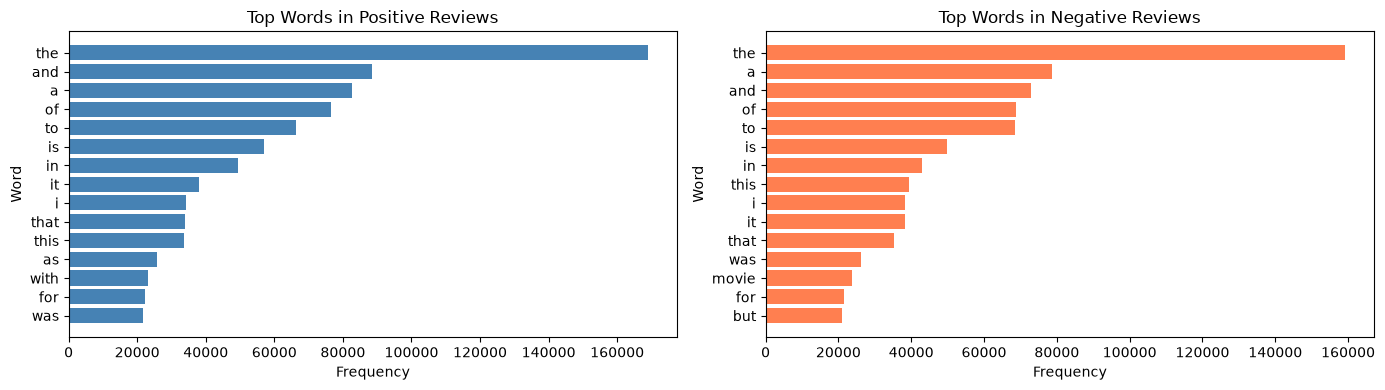

In [11]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt


pos_text = ' '.join(
    df_train[df_train['label'] == 1]['clean_text']
)

neg_text = ' '.join(
    df_train[df_train['label'] == 0]['clean_text']
)


pos_words = Counter(pos_text.split()).most_common(15)
neg_words = Counter(neg_text.split()).most_common(15)


pos_df = pd.DataFrame(pos_words, columns=['word', 'count'])
neg_df = pd.DataFrame(neg_words, columns=['word', 'count'])


fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].barh(
    pos_df['word'],
    pos_df['count'],
    color='steelblue'
)
axes[0].set_title('Top Words in Positive Reviews')
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('Word')
axes[0].invert_yaxis()

axes[1].barh(
    neg_df['word'],
    neg_df['count'],
    color='coral'
)
axes[1].set_title('Top Words in Negative Reviews')
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('Word')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('top_words_by_sentiment.png')
plt.show()


**Interpretation:**

The top-word charts show that common English words such as "the", "and", "a", and "of" appear frequently in both positive and negative reviews. The two charts have considerable overlap, and the most frequent words are mostly common grammatical words rather than sentiment-specific terms. Since these common words do not clearly distinguish sentiment, removing stop words or examining sentiment-related words could provide more useful insights into the differences between positive and negative reviews.

In [12]:
positive_vocab = set(pos_text.split())
negative_vocab = set(neg_text.split())

negative_only_words = negative_vocab - positive_vocab

print("Negative-only words:")
print(sorted(negative_only_words)[:50])

print("Total:", len(negative_only_words))

Negative-only words:
['aaaaaaah', 'aaaaah', 'aaaahhhhhhh', 'aaaarrgh', 'aaah', 'aaarghhow', 'aaaugh', 'aadmittedly', 'aaghh', 'aah', 'aahhh', 'aaip', 'aaja', 'aakash', 'aankh', 'aap', 'aargh', 'aasize', 'aauugghh', 'abanazer', 'abandonof', 'abas', 'abashed', 'abattoirs', 'abbu', 'abcd', 'abcsears', 'abcthe', 'abdic', 'abdicates', 'abdomen', 'abductee', 'abductions', 'abduhamdi', 'abdullah', 'abdulrahman', 'abercrombie', 'abernathy', 'abetting', 'abhisheh', 'abhorrence', 'abhorrentthen', 'abilitiesthe', 'abilityi', 'abilitymost', 'abilitythe', 'abilitythere', 'abisheks', 'abkani', 'ablazeso']
Total: 47974


In [13]:
from collections import Counter

negative_only_counts = Counter(
    word
    for text in df_train[df_train['label'] == 0]['clean_text']
    for word in text.split()
    if word in negative_only_words
)

print("Top 30 most frequent negative-only words:")
print(negative_only_counts.most_common(30))

Top 30 most frequent negative-only words:
[('slater', 41), ('hobgoblins', 41), ('tashan', 40), ('kornbluth', 35), ('kareena', 35), ('btk', 34), ('sarne', 34), ('welch', 32), ('darkman', 31), ('delia', 30), ('manos', 29), ('tremors', 29), ('kibbutz', 28), ('shaq', 27), ('hackenstein', 27), ('saif', 27), ('rosanna', 26), ('savini', 26), ('mraovich', 26), ('gram', 25), ('zenia', 25), ('weisz', 24), ('dyer', 24), ('orca', 23), ('dunaway', 22), ('crapfest', 22), ('palermo', 22), ('kazaam', 21), ('louque', 21), ('hallam', 21)]


**Interpretation: Words Exclusive to Negative Reviews**

The vocabulary comparison identified 47,974 unique words that appeared in negative reviews but not in positive reviews. The most frequent negative-only words include names and movie-related terms such as "slater", "hobgoblins", "tashan", and "darkman", rather than exclusively negative sentiment expressions. This shows that vocabulary exclusivity does not necessarily indicate negative sentiment, as some words may be associated with specific movies, actors, or topics. Further text preprocessing and analysis of word usage in context could help identify more meaningful sentiment patterns.

============================================================= SECTION 5 - LOGISTIC REGRESSION BASELINE ==============================================================

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

y_train = df_train['label'].values
y_test = df_test['label'].values

lr_model = LogisticRegression(max_iter=1000, C=1.0)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

print('Accuracy:', round(accuracy_score(y_test, y_pred_lr), 4))

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=['Negative', 'Positive']
    )
)

Accuracy: 0.8756
              precision    recall  f1-score   support

    Negative       0.88      0.87      0.87     12500
    Positive       0.87      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



### Interpretation: Model Performance

My Logistic Regression model achieved an accuracy of **87.56%** on the test dataset, correctly classifying 21,891 out of 25,000 movie reviews. I think this is a good baseline result for a traditional machine learning model using TF-IDF features.

The precision, recall, and F1-scores for both positive and negative reviews are around 0.87–0.88, which shows that the model performs fairly consistently across both sentiment classes. Since the dataset contains an equal number of positive and negative reviews, the results give us a useful starting point for comparing this model with more advanced models later.

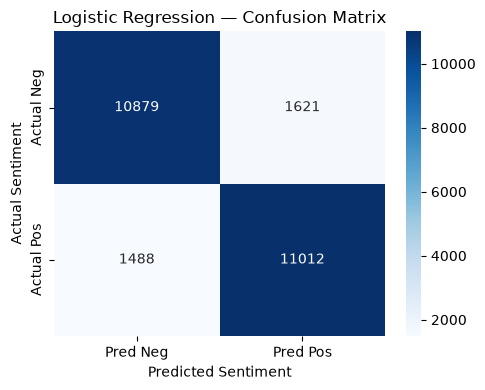

In [15]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Pred Neg', 'Pred Pos'],
    yticklabels=['Actual Neg', 'Actual Pos']
)

plt.title('Logistic Regression — Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.tight_layout()
plt.savefig('lr_confusion_matrix.png')
plt.show()

In [16]:
coefs = lr_model.coef_[0]

top_pos = np.argsort(coefs)[-10:][::-1]
top_neg = np.argsort(coefs)[:10]

print('Words most predictive of POSITIVE:')
print([feature_names[i] for i in top_pos])

print('\nWords most predictive of NEGATIVE:')
print([feature_names[i] for i in top_neg])

Words most predictive of POSITIVE:
['great', 'excellent', 'best', 'perfect', 'wonderful', 'favorite', 'amazing', 'loved', 'enjoyed', 'today']

Words most predictive of NEGATIVE:
['worst', 'waste', 'awful', 'bad', 'boring', 'poor', 'worse', 'poorly', 'dull', 'terrible']


### Interpretation: Confusion Matrix and Predictive Words

The confusion matrix shows that the model correctly classified 10,879 negative reviews and 11,012 positive reviews. However, it incorrectly classified 1,621 negative reviews as positive and 1,488 positive reviews as negative. This suggests that the model makes mistakes in both directions, although it identifies the correct sentiment for most reviews.

The predictive words make sense to me because words such as "excellent", "wonderful", and "amazing" are commonly used to express positive opinions, while words such as "awful", "boring", and "terrible" usually express negative opinions. This suggests that the model has learned meaningful associations between words and sentiment. However, it may still struggle with sarcasm, mixed opinions, or reviews where the meaning depends on context.

============================================================== SECTION 6 - MODEL COMPARISON & EDA REPORT ===========================================================

In [17]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print(
    'Naive Bayes Accuracy:',
    round(accuracy_score(y_test, y_pred_nb), 4)
)

Naive Bayes Accuracy: 0.8398


                 Model  Accuracy
0  Logistic Regression   0.87564
1          Naive Bayes   0.83984


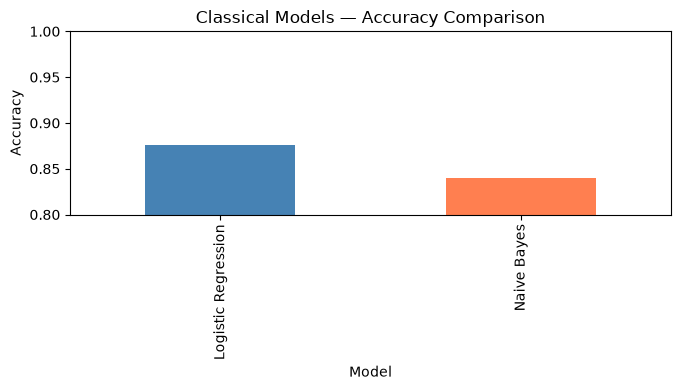

In [18]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb)
    ]
})

print(results)

results.plot(
    kind='bar',
    x='Model',
    y='Accuracy',
    figsize=(7, 4),
    color=['steelblue', 'coral'],
    legend=False
)

plt.title('Classical Models — Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.8, 1.0)
plt.tight_layout()
plt.savefig('model_comparison.png')
plt.show()

## KEY FINDINGS

### Finding 1: Logistic Regression achieved 87.56% accuracy on 25,000 test reviews.

**Meaning:** Logistic Regression performed well using TF-IDF features, which suggests that word frequency and word importance capture useful patterns for identifying sentiment in movie reviews.

**Action:** I'll use Logistic Regression as my baseline benchmark and compare future models against this score.

### Finding 2: Naive Bayes achieved 83.98% accuracy, which is 3.58 percentage points lower than Logistic Regression.

**Meaning:** Both models were able to identify sentiment, but Logistic Regression made more correct predictions on this dataset. It correctly classified 895 more test reviews than Naive Bayes.

**Action:** I'll keep both results for reference and use the same test dataset when evaluating other models to ensure a fair comparison.

### Finding 3: Logistic Regression is the stronger of the two classical models in this experiment.

**Meaning:** The comparison shows that a traditional machine learning model can already achieve good results on sentiment analysis. However, accuracy alone doesn't tell the whole story, and these results don't guarantee that Logistic Regression will perform better on every dataset.

**Action:** I'll use Logistic Regression's 87.56% accuracy as the current benchmark and later evaluate a transformer-based model to see whether it can improve performance.

========================================================= SECTION 7 - NEURAL NETWORK (ANN) ==============================================================

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

X_tr = torch.FloatTensor(X_train_tfidf.toarray())
X_te = torch.FloatTensor(X_test_tfidf.toarray())

y_tr = torch.tensor(y_train.copy(), dtype=torch.long)
y_te = torch.tensor(y_test.copy(), dtype=torch.long)
train_ds = TensorDataset(X_tr, y_tr)
train_dl = DataLoader(
    train_ds,
    batch_size=256,
    shuffle=True
)

class SentimentANN(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(X_train_tfidf.shape[1], 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

model_ann = SentimentANN()

optimizer = torch.optim.Adam(
    model_ann.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

print("Input features:", X_train_tfidf.shape[1])
print("ANN model initialized successfully!")


Input features: 5000
ANN model initialized successfully!


In [21]:
losses = []

for epoch in range(5):
    model_ann.train()
    total_loss = 0

    for xb, yb in train_dl:
        optimizer.zero_grad()

        outputs = model_ann(xb)
        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_dl)
    losses.append(avg_loss)

    print(f'Epoch {epoch + 1}/5 — Loss: {avg_loss:.4f}')

Epoch 1/5 — Loss: 0.4324
Epoch 2/5 — Loss: 0.2333
Epoch 3/5 — Loss: 0.1990
Epoch 4/5 — Loss: 0.1741
Epoch 5/5 — Loss: 0.1432


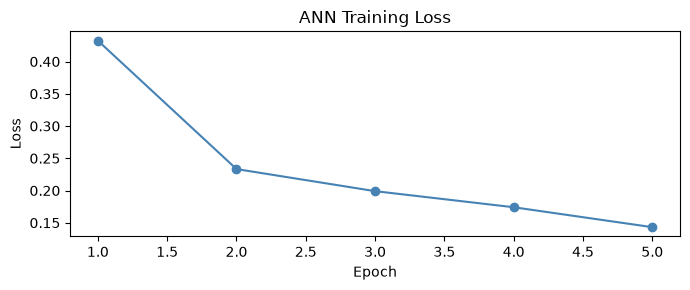

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))

plt.plot(
    range(1, 6),
    losses,
    marker='o',
    color='steelblue'
)

plt.title('ANN Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.savefig('ann_loss.png')
plt.show()

In [23]:
from sklearn.metrics import accuracy_score

model_ann.eval()

with torch.no_grad():
    preds = model_ann(X_te).argmax(dim=1).numpy()

ann_accuracy = accuracy_score(y_test, preds)

print('ANN Accuracy:', round(ann_accuracy, 4))
print('Logistic Regression Accuracy:', round(
    accuracy_score(y_test, y_pred_lr), 4
))

ANN Accuracy: 0.8501
Logistic Regression Accuracy: 0.8756


### Interpretation - Neural Network Baseline

My ANN achieved **85.01% accuracy**, while Logistic Regression achieved **87.56%** on the same test dataset of 25,000 reviews. I expected the neural network to perform better, but Logistic Regression actually gave better results in this experiment. This shows that a more complex model does not always outperform a simpler one, especially when both use TF-IDF features.

The training loss decreased steadily from **0.4324 in the first epoch to 0.1432 in the fifth epoch**, which suggests that the ANN learned useful patterns from the training data. However, its lower test accuracy indicates that learning the training data does not necessarily translate into better predictions on unseen reviews. In future experiments, I can explore model tuning and transformer-based approaches to see whether I can improve the results.

=============================================================== SECTION 8 - TRANSFORMER MODEL (DISTILBERT) ======================================================

In [24]:
from transformers import pipeline

sentiment_model = pipeline(
    'sentiment-analysis',
    model='distilbert-base-uncased-finetuned-sst-2-english',
    truncation=True,
    max_length=512
)

print("DistilBERT sentiment model loaded successfully!")

C:\Users\Shria\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Shria\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Shria\AppData\Local\Programs\Python\Python314\Lib\site-pac

DistilBERT sentiment model loaded successfully!


In [26]:
from sklearn.metrics import accuracy_score, classification_report

sample_df = df_test.sample(
    500,
    random_state=42
).reset_index(drop=True)

sample_texts = sample_df['clean_text'].tolist()

raw_preds = sentiment_model(
    sample_texts,
    batch_size=32
)

pred_labels = [
    1 if p['label'] == 'POSITIVE' else 0
    for p in raw_preds
]

true_labels = sample_df['label'].tolist()

print(
    'Transformer Accuracy (500 samples):',
    round(accuracy_score(true_labels, pred_labels), 4)
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=['Negative', 'Positive']
    )
)

Transformer Accuracy (500 samples): 0.864
              precision    recall  f1-score   support

    Negative       0.84      0.92      0.88       266
    Positive       0.90      0.80      0.85       234

    accuracy                           0.86       500
   macro avg       0.87      0.86      0.86       500
weighted avg       0.87      0.86      0.86       500



In [27]:
my_reviews = [
    "This movie was absolutely brilliant, I loved every minute!",
    "Terrible film. Waste of time and money.",
    "It was okay, nothing special but not bad either."
]
results = sentiment_model(my_reviews)
for review, result in zip(my_reviews, results):
    print(f'Review: {review[:60]}...')
    print(f'Prediction: {result["label"]} (confidence: {result["score"]:.2f})')
    print()

Review: This movie was absolutely brilliant, I loved every minute!...
Prediction: POSITIVE (confidence: 1.00)

Review: Terrible film. Waste of time and money....
Prediction: NEGATIVE (confidence: 1.00)

Review: It was okay, nothing special but not bad either....
Prediction: POSITIVE (confidence: 0.99)



**Interpretation: Model Comparison**

**Logistic Regression** achieved the highest accuracy of **87.56%**, followed by **DistilBERT** at **86.40%** and **ANN** at **85.01%.**
DistilBERT performed well on clearly positive and negative reviews, while ANN had slightly lower accuracy than the other two models.
However, Logistic Regression and ANN were tested on 25,000 reviews, whereas DistilBERT was tested on only 500 reviews, so testing all three models on the same dataset would give a fairer comparison.

============================================================== SECTION 9 - MODEL COMPARISON REPORT ======================================================

In [28]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Naive Bayes', 'ANN', 'DistilBERT (sample)'],
    'Accuracy': [
        round(accuracy_score(y_test, y_pred_lr), 4),
        round(accuracy_score(y_test, y_pred_nb), 4),
        round(accuracy_score(y_test, preds), 4),
        round(accuracy_score(true_labels, pred_labels), 4)
    ],
    'Type': ['Classical ML', 'Classical ML', 'Deep Learning', 'Transformer']
})
print(comparison)

                 Model  Accuracy           Type
0  Logistic Regression    0.8756   Classical ML
1          Naive Bayes    0.8398   Classical ML
2                  ANN    0.8501  Deep Learning
3  DistilBERT (sample)    0.8640    Transformer


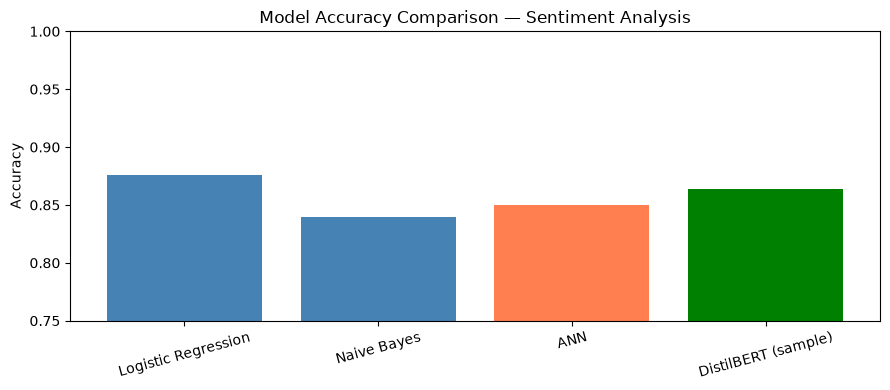

In [29]:
colors = ['steelblue', 'steelblue', 'coral', 'green']
plt.figure(figsize=(9, 4))
plt.bar(comparison['Model'], comparison['Accuracy'], color=colors)
plt.title('Model Accuracy Comparison — Sentiment Analysis')
plt.ylabel('Accuracy')
plt.ylim(0.75, 1.0)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('final_model_comparison.png')
plt.show()

**KEY FINDINGS - Model Comparison**

Finding 1: Logistic Regression - 87.56% accuracy
- Meaning: Logistic Regression achieved the highest accuracy among the four models.
- Action: Keep it as the current baseline because it performs well without the extra computational cost of a transformer.

Finding 2: Naive Bayes - 83.98% accuracy
- Meaning: Naive Bayes was the fastest and simplest type of model to try, but it had the lowest accuracy.
- Action: Use it as a lightweight baseline for comparison with more advanced models.

Finding 3: ANN - 85.01% accuracy
- Meaning: The neural network performed better than Naive Bayes but did not outperform Logistic Regression.
- Action: Experiment with the network architecture and training settings if further improvements are needed.

Finding 4: DistilBERT - 86.40% accuracy
- Meaning: DistilBERT performed competitively, coming close to Logistic Regression, although it was evaluated on only 500 reviews.
- Action: Test it on the same full test set before deciding whether its additional computational cost is worthwhile.
  
Note: Logistic Regression and ANN were evaluated on 25,000 reviews, while DistilBERT was evaluated on 500. Their accuracy scores are therefore not directly comparable.